### Run Model

In [2]:

from time import perf_counter
import math
import aerosandbox as asb

from solver.geometry import (
    WingParameters,
    build_wing_geometry,
    to_aerosandbox_wing,
)

# Build a symmetric, unswept wing.
parameters = WingParameters(
    aspect_ratio=8.0,
    area_m2=1.0,
    taper_ratio=0.5,
    sweep_deg=0.0,
    airfoil="naca0012",
)

geometry = build_wing_geometry(parameters)
wing = to_aerosandbox_wing(geometry)

airplane = asb.Airplane(
    name="VLM notebook test",
    wings=[wing],
    s_ref=parameters.area_m2,
    b_ref=geometry.span_m,
    c_ref=wing.mean_aerodynamic_chord(),
)

analysis = asb.VortexLatticeMethod(
    airplane=airplane,
    op_point=asb.OperatingPoint(
        velocity=20.0,  # m/s
        alpha=5.0,      # degrees
        beta=0.0,
    ),
    spanwise_resolution=20,
    chordwise_resolution=4,
)

start = perf_counter()
aero = analysis.run()
runtime_s = perf_counter() - start

cl = float(aero["CL"])
cd = float(aero["CD"])

assert math.isfinite(cl), "CL is not finite"
assert math.isfinite(cd), "CD is not finite"
assert cl > 0, "Expected positive lift for this positive-angle test"
assert cd >= 0, "Expected nonnegative induced drag"

print(f"Geometry ID: {geometry.geometry_id}")
print(f"CL: {cl:.6f}")
print(f"CD, inviscid VLM: {cd:.6f}")
print(f"Solver execution time: {runtime_s:.4f} s")

Geometry ID: wing_126480edad821890d75a
CL: 0.415989
CD, inviscid VLM: 0.006767
Solver execution time: 0.1898 s


c:\Users\hayes\anaconda3\Lib\site-packages\aerosandbox\geometry\airplane.py:396: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install trame-pyvista
  fig.plot(**show_kwargs)


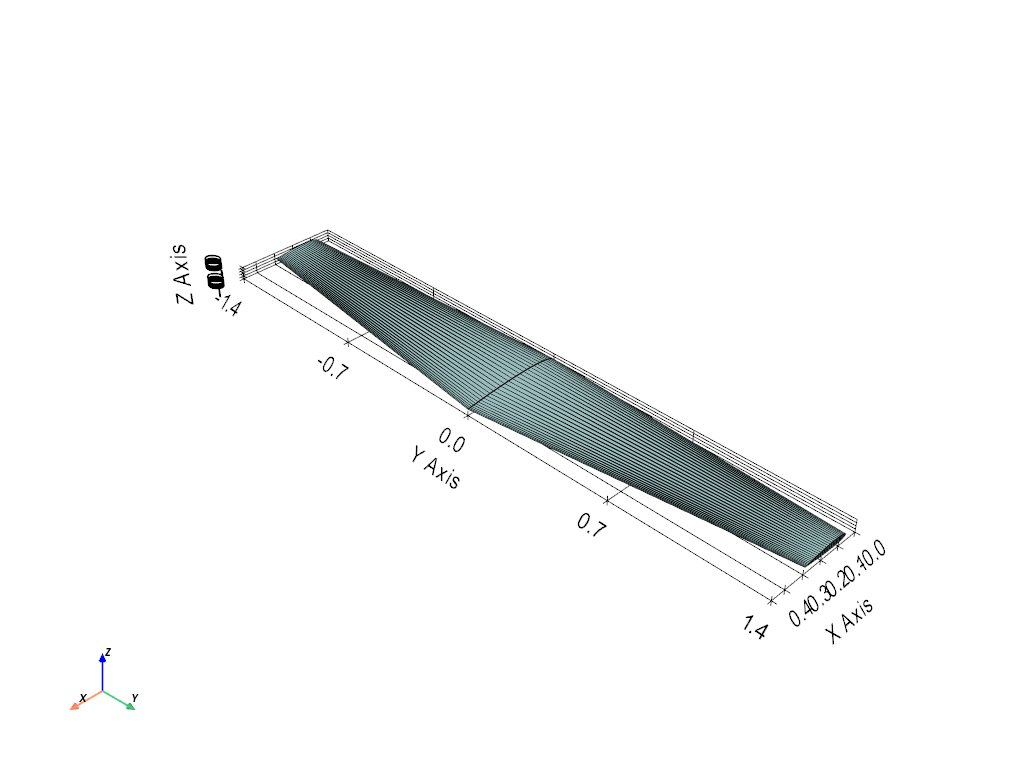

PolyData (0x2726d4d8d60)
  N Cells:    290
  N Points:   292
  N Strips:   0
  X Bounds:   -7.736e-22, 4.714e-01
  Y Bounds:   -1.414e+00, 1.414e+00
  Z Bounds:   -2.826e-02, 2.826e-02
  N Arrays:   0

In [3]:
airplane.draw()